# 02 · Well correlation

The correlate stage aligns all wells to a shared relative-geologic-time axis (`layer_time`) by dynamic time
warping ([Sakoe & Chiba 1978](https://doi.org/10.1109/TASSP.1978.1163055)) between neighboring wells, solved
jointly in the spirit of [Wheeler & Hale (2014)](https://doi.org/10.1190/segam2014-0227.1), with formation
tops as anchors. Run notebook 01 first.

## Setup
Set `SX_EXAMPLE_PROJECT` to your KGS project folder (default `kgs_project/` next to this notebook).

In [1]:
import os
from pathlib import Path
import numpy as np, pandas as pd, pyarrow.parquet as pq
import matplotlib.pyplot as plt
%matplotlib inline
# SX_EXAMPLE_PROJECT: KGS project folder (las/, edges/, project.toml), see scripts/fetch_open_data.sh.
# SX_EXAMPLE_OUT: folder for figures and the small model files passed between notebooks.
PROJ = Path(os.environ.get("SX_EXAMPLE_PROJECT", "kgs_project")).resolve()
OUT = Path(os.environ.get("SX_EXAMPLE_OUT", "outputs")).resolve()
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 110})
def save(fig, name):
    fig.savefig(OUT / name, bbox_inches="tight")

## Load the stage outputs

In [2]:
wells = pq.read_table(PROJ / "export/wells.parquet").to_pandas()
tops = pq.read_table(PROJ / "export/tops.parquet").to_pandas()
lt = pq.read_table(PROJ / "export/layer_time.parquet").to_pandas()
geo = pq.read_table(PROJ / "export/geometry.parquet").to_pandas()
fin = pq.read_table(PROJ / "export/logs_final.parquet", columns=["well_id", "k", "gr_api"]).to_pandas()
print(len(wells), "wells;", int(tops.suspect.sum()), "of", len(tops), "tops flagged suspect")
tops.groupby("top_name").agg(n=("md_ft", "size"), suspect=("suspect", "sum"), mean_elev_ft=("elev_ft", "mean")).sort_values("mean_elev_ft", ascending=False)

60 wells; 17 of 960 tops flagged suspect


,n,suspect,mean_elev_ft
top_name,,,
Heebner,60,0,-2300.181034
Douglas,60,0,-2340.475000
Stark,60,0,-2992.142857
Hushpuckney,60,0,-3025.779070
Hertha,60,1,-3026.916667
Pawnee,60,1,-3160.793103
Cherokee,60,1,-3197.410714
Cherokee Sand,60,1,-3241.611111
Mississippian,60,2,-3248.330508


## West–east section
Left: GR on elevation with three tops. Right: the same curves on `layer_time`, where correlated beds line up.

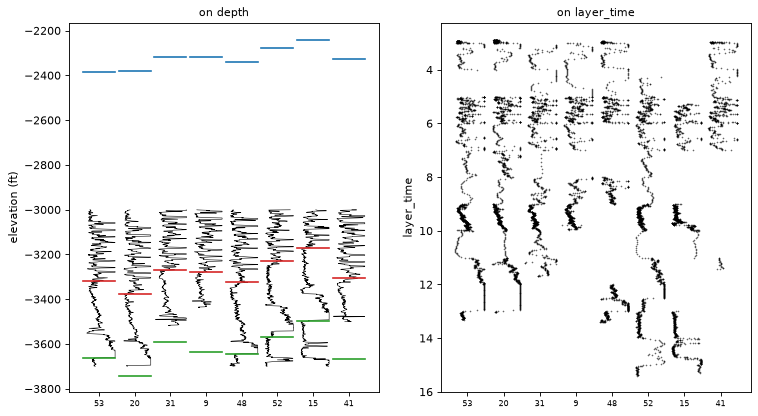

In [3]:
sel = wells.sort_values("x_m").iloc[:: max(1, len(wells) // 8)].head(8)
d = fin.merge(lt, on=["well_id", "k"]).merge(geo[["well_id", "k", "elev_ft"]], on=["well_id", "k"])
colors = {"Heebner": "tab:blue", "Mississippian": "tab:red", "Viola": "tab:green"}
fig, axs = plt.subplots(1, 2, figsize=(11, 6))
for i, w in enumerate(sel.well_id):
    s = d[(d.well_id == w) & (d.elev_ft < -3000) & (d.elev_ft > -3700)]
    g = (s.gr_api.clip(0, 150) / 150) * 0.9 + i
    axs[0].plot(g, s.elev_ft, lw=0.5, color="k"); axs[1].plot(g, s.layer_time, ".", ms=0.6, color="k")
    for _, row in tops[(tops.well_id == w) & tops.top_name.isin(list(colors))].iterrows():
        axs[0].plot([i, i + 0.9], [row.elev_ft] * 2, color=colors[row.top_name], lw=1.5)
axs[0].set_ylabel("elevation (ft)"); axs[1].set_ylabel("layer_time"); axs[1].invert_yaxis()
for ax, t in zip(axs, ["on depth", "on layer_time"]):
    ax.set_title(t, fontsize=10); ax.set_xticks(np.arange(len(sel)) + 0.45); ax.set_xticklabels(sel.well_id, fontsize=7)
save(fig, "02_correlation_section.png")

## Top consistency
Spread of each top among neighboring wells after correlation; large spreads point to tops worth checking.

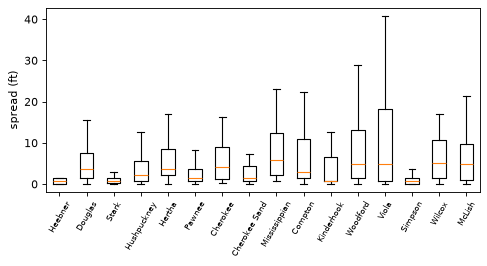

In [4]:
order = tops.groupby("top_name").elev_ft.mean().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(7, 3))
ax.boxplot([tops[tops.top_name == n].spread_ft.dropna() for n in order], tick_labels=list(order), showfliers=False)
ax.set_ylabel("spread (ft)"); ax.tick_params(axis="x", rotation=60, labelsize=7)
save(fig, "02_top_spread.png")

The same workflow runs on the FORCE 2020 North Sea wells ([Bormann et al. 2020](https://doi.org/10.5281/zenodo.4351155)):
fetch them with `scripts/fetch_force2020.sh`, convert with `force2020_to_las.py`, and use `force2020_project.toml`.